# TD 1 : Introduction to R and Descriptive Statistics

Matthias Grenié & Christelle Gonindard

## 1 Introduction

### 1.1 Overview of this year's course expectations

These courses are designed to give you the necessary hindsight to interpret the statistical analyses
that you will be called upon to evaluate in the course of your studies and professional life.
The most important thing is to understand the principle of the analysis used and to form your own opinion in order to disentangle the true from the false.
your own opinion in order to sort out the true from the false. The aim is not to turn you into
statisticians who will develop new methods, but that you will be able to understand
to understand and detect potential errors and biases that can lead to misinterpretation of data and erroneous conclusions.


### 1.2 Background

As described in the course, it is important to be aware that statistics
are linked to the medical field. They really came into their own and contributed to medical improvements
to understand the causes of disease, the spread of epidemics and so on.
the spread of epidemics... 

Below is a non-exhaustive list of areas in which statistics
application of statistics in pharmacy:
- When developing a new drug, three verification stages must be respected:
1. Is the new drug non-toxic to humans?
2. Is the new drug effective?
3. Is the new drug more effective than existing treatments?
- When developing a new diagnostic test or analysis method, the following questions are asked:
1. Does the new diagnostic test do a better job than mere chance of giving a positive result to a patient who is really ill?
2. Does the new analysis method do as well as its predecessor?
3. Does the new diagnostic test improve sensitivity (ability to give a positive result to a really sick person)?
- In an epidemiological study, the following questions are asked:
1. Does exposure to a factor have an effect on the occurrence of the disease?
2. Is it possible to predict the risk of disease occurrence following exposure to this factor?
3. Study the impact of a treatment on patient death at 30 days, all other things being equal.
- When assessing the quality and control of a production line
- When assessing the resources and health status of a population: causes of death, morbidity, health surveillance....

In conclusion, in biology or health, the fields of application are vast: randomized clinical trials, epidemiological studies, etc.
randomized clinical trials, epidemiological studies, population dynamics, omics studies
(genomics, proteomics, transcriptomics, etc.), production lines .... These studies represent
a considerable mass of data to process. Long gone are the days when statistical calculations
were done by hand, on small samples. To process the data, it is now necessary to use
computer software. The most important thing to remember about this EU course is that it is very comprehensive.
to analyze and interpret a medical study:
- master the medical knowledge needed to understand the data and interpret the results 
- understand the principles of different statistical methods, so as to know which one to use depending on the sample and the questions asked
- master a minimum level of computer skills, as the data to be processed is becoming so important that it is illusory to attempt calculations by hand.


## 2. Data presentation

**Session objective**

**Based on a proposed data set and the biological problem raised, the aim is to
describe the sample, an essential step prior to any statistical analysis through the R programming language**.

A clinician evaluates the intensity of depression on the Hamilton scale, which ranges from 0 (not depressed) to
56 (very depressed), in 100 patients suffering from a Major Depressive Episode (MDE).
We want to know whether acupuncture improves the course of depression. To this end, 100 patients
with the same depressive state (same Hamilton score) were divided into 2 groups of 50 by drawing lots.
by lot. Group I received pharmacological treatment only, while Group II received pharmacological treatment combined with acupuncture.
pharmacological treatment combined with acupuncture.
The dataset contains the following variables:
- `hamilton_g1`: Hamilton scores, after 8 months of treatment, for patients of group I;
- `hamilton_g2`: Hamilton scores, after 8 months of treatment, for patients of group II;
- `urbanization_g1`: level of urbanization in which patients live (A: rural, B: moderate urbanization, C: highly urbanized) for patients of group I;
- `urbanization_g2`: level of urbanization in which patients live (A: rural, B: moderate urbanization, C: highly urbanized) for patients of group II;
- `age_g1`: patients' age in years for group I;
- `age_g2`: patients' age in years for group II;
- `weight_g1`: patients' weight in kilograms for group I;
- `weight_g2`: patients' weight in kilograms for group II;
- `sex_g1`: patients' gender in group I;
- `sex_g2`: patients' gender in group II.

The data is contained in the text file `data_depression.txt` in the `data/` directory, whose full path is `data/data_depression.txt`.

Data are read using R's `read.table()` function:


To execute your instruction, simply click on the **Run** button or press “ctrl+enter”.

In [1]:
# Read data
depression = read.table("data/data_depression.txt", header = TRUE)

A table can contain several thousand rows, so displaying them all may be pointless.

The `head()` function displays the first lines of a table.

In [2]:
# Display the beginning of the data file content
head(depression)

,hamilton_g1,hamilton_g2,urbanization_g1,urbanization_g2,age_g1,age_g2,weight_g1,weight_g2,sex_g1,sex_g2
,<int>,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<chr>
1,43,25,B,B,57,48,74,93,F,H
2,29,29,A,B,37,41,95,92,H,H
3,34,18,A,A,7,30,84,86,H,H
4,39,23,A,A,37,41,104,81,H,H
5,40,24,B,A,15,30,92,74,H,F
6,41,25,B,B,45,45,85,98,H,H


In **R**, a one-dimensional set is called a vector; for example, a table column is a vector.  
You can call it using the dollar symbol **`$`** from the table name you assigned before.

In [3]:
# Display the contents of column Hamilton_G1
# Note: to access columns, specify variable name
depression$hamilton_g1

[1] 43 29 34 39 40 41 32 36 35 37 43 36 41 37 33 40 38 43 32 32 44 40 36 37 41
[26] 43 37 31 47 41 45 42 46 35 49 33 34 44 40 42 44 40 29 36 42 44 32 37 42 45

## 3. Descriptive statistics

Descriptive statistics is the first essential step in statistical analysis,
This step will obviously enable you to summarize or represent the observed data, with as few words, figures or graphs as possible.
with as few words, figures or graphs as possible, using simple statistical tools such as
mean, median, variance, quantiles, maximum, minimum....
It can also be used to check for erroneous values and sampling problems.

It can also be used to suggest hypotheses for further study, or to check the conditions of application for statistical tests in the inferential study that follows.

### 3.1 Random variables

The variables in a dataset can take on a certain number of values, which cannot be
can be predicted a priori, which is why they are called random variables. There
are two types of random variable:
- Qualitative variable: modality that cannot be measured, e.g. eye color, sex,
blood type...
- Quantitative variable: measurable modality, e.g. height, hormone level, etc.

A random variable is said to be discrete if it takes only discontinuous values within a given interval.
for example, the number of children in a family, the number of smokers...

A random variable is said to be continuous if it takes all values within a given interval,
e.g. height, weight...

In our course example, the variables **Hamilton**, **age** and **weight** are quantitative variables
while **sex** and **urbanization** are qualitative variables.

### 3.2 Parameters most commonly used in descriptive statistics

When describing a dataset, two types of parameters must be used
to describe quantitative variables: positional parameters and dispersion parameters.

#### Positional parameters

1. the **mean**: the weighted sum of measured values 
2. the **median**: this is the value that divides the sample in two, so that 50% of observations are above this value and 50% of observations are below it.

Comparing these two indicators :

1. the **average**: this is the familiar, intuitive and easy-to-calculate indicator. Its weak point: it's not robust (it's very sensitive to changes in one or more observations, extreme values, etc.).
2. the **median**: this indicator is both precise and robust (it is not very sensitive to changes in one or more observations or extreme values...).

Note: throughout the tutorials, you'll find R language instructions for carrying out statistical analyses in the boxes.

*Application to the Hamilton score data set:*

*Application* : compute means (with function `mean()`) and medians (with function `median()`) of variables `age_g1` and `weight_g1`

In [4]:
#### Age variable
# Average of the variable 
mean(depression$age_g1)

# Variable median
median(depression$age_g1)

#### Weight variable
# Variable mean 
mean(depression$weight_g1)

# Median of the variable
median(depression$weight_g1)


[1] 40.42

[1] 41

[1] 83.54

[1] 82

**Comparison of averages between several groups**

We want to compare the Hamilton scores of Group 1 and Group 2, and their respective ages. 

To do this, we'll create 4 variables:

- `hamilton_g1`, which will contain the Hamilton score of group 1;
- `hamilton_g2`, which will contain the Hamilton score of group 2;
- `age_g1`, which will contain the age of patients in group 1;
- `age_g2`, which will contain the age of patients in group 2.

In [5]:
# 'hamilton_g1', which will contain the Hamilton score of group 1
hamilton_g1 = depression$hamilton_g1
hamilton_g1

# 'hamilton_g2', which will contain the Hamilton score of group 2
hamilton_g2 = depression$hamilton_g2

# 'age_g1', which will contain the age of patients in group 1
age_g1 = depression$age_g1

# 'age_g2', which will contain the age of patients in group 2
age_g2 = depression$age_g2

[1] 43 29 34 39 40 41 32 36 35 37 43 36 41 37 33 40 38 43 32 32 44 40 36 37 41
[26] 43 37 31 47 41 45 42 46 35 49 33 34 44 40 42 44 40 29 36 42 44 32 37 42 45

In [6]:
# Calculate the average of hamilton_G1
mean(hamilton_g1)

# Calculate average hamilton_G2
mean(hamilton_g2)


# Calculate average of age_G1
mean(age_g1)

# Calculate average of age_G2
mean(age_g2)


[1] 38.78

[1] 24.54

[1] 40.42

[1] 36.88

**Comment**

We observe that the average Hamilton score of people in groupe II is lower than the ones in group I.
This could let us think that acupuncture reduces depression.  
However, we also see that the average age of people in group II is lower than in group I, so this difference may be due to the difference in age between groups.

It's important to check the dispersion of the data, because even if the difference in means between the two groups may seem large, there are two possible scenarios:
- if the standard deviation for both groups is equally large, then this difference is reduced, and the data overlap
- if the standard deviation is low, then the two groups have very distinct data, and the difference between the two groups becomes clear. 

#### Dispersion parameters

They determine the variability of measurements in relation to a positional parameter.

1. variance: this is the deviation from the mean; the standard deviation is the root of the variance.
2. amplitude: the difference between the largest and smallest values observed in the sample.
3. inter-quartile range: this is the range of values delimited by the 1st and 3rd quartiles (Q1 and Q3 respectively). It contains 50% of observations: 25% on either side of the median. Quartiles are defined on the same principle as the median (also called 2nd quartile).

**Q1** (first quartile): this is the value that divides the sample in two, such that 75% of observations
are above this value and 25% of observations are below it.

**Q3** (third quartile): this is the value that splits the sample in two so that 25% of observations are above this value and 75% are below it.
are above this value and 75% of observations are below it.

Comparison of these three indicators :
1. the standard deviation: not a very robust indicator, but easy to calculate and a recurring one in inferential statistics
2. the inter-quartile range: this is a robust indicator, as are the values that characterize it (quartiles).
3. amplitude: easy to calculate, but highly sensitive to outliers (generally extreme values).

*Application to the Hamilton score dataset:*

Compute the mean, median, standard deviation (with function `sd()`) and general summary statistics (with function `summary()`) of `hamilton_g1`

In [7]:
# Average of hamilton_g1 variable
mean(hamilton_g1)

# Median of hamilton_g1 variable
median(hamilton_g1)

# Standard deviation of the variable hamilton_g1
sd(hamilton_g1)

# Statistic summary of the variable hamilton_g1
summary(hamilton_g1)

[1] 38.78

[1] 40

[1] 4.896021

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  29.00   35.25   40.00   38.78   42.75   49.00 

Calculate the mean, median, standard deviation and statistical summary for the variable `hamilton_g2` and compare with the results obtained for the variable `hamilton_g1`.

In [8]:
mean(hamilton_g2)
median(hamilton_g2)
sd(hamilton_g2)
summary(hamilton_g2)

[1] 24.54

[1] 25

[1] 5.006975

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  15.00   20.50   25.00   24.54   28.00   36.00 

**Conclude**: 

Overall we observe that both groups show the same standard deviation in Hamilton scores. However, group II is overall lower, in extremums as well as in mean and quartiles.

### 3.3 Representation of quantitative variables

#### The histogram

The histogram is a quick way to study the distribution of a variable.
However, care must be taken, as the shape of the histogram changes according to the amplitude of the classes.
You need to test several steps, i.e., several different breakdowns.

P.Besse: “The quality of the estimation of a distribution by a histogram depends very much on
on the division into classes. Unfortunately, rather than providing classes of equal size
and thus distribute the imprecision more evenly, software programs use classes with equal amplitudes, thus
histograms that are sometimes unrepresentative.

You can plot a histogram in R with function `hist()`.

*Application to the Hamilton score data set:*

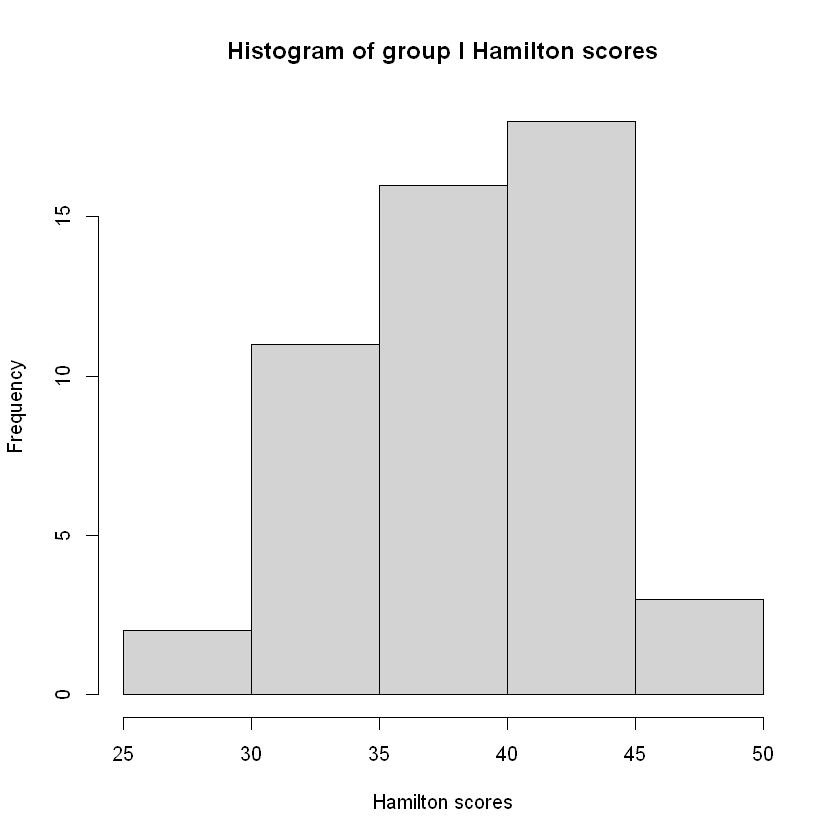

In [9]:
# Histogram of hamilton_g1 variable
hist(hamilton_g1, main = "Histogram of group I Hamilton scores", xlab = "Hamilton scores")

Compare this histogram to the one of `hamilton_g2`

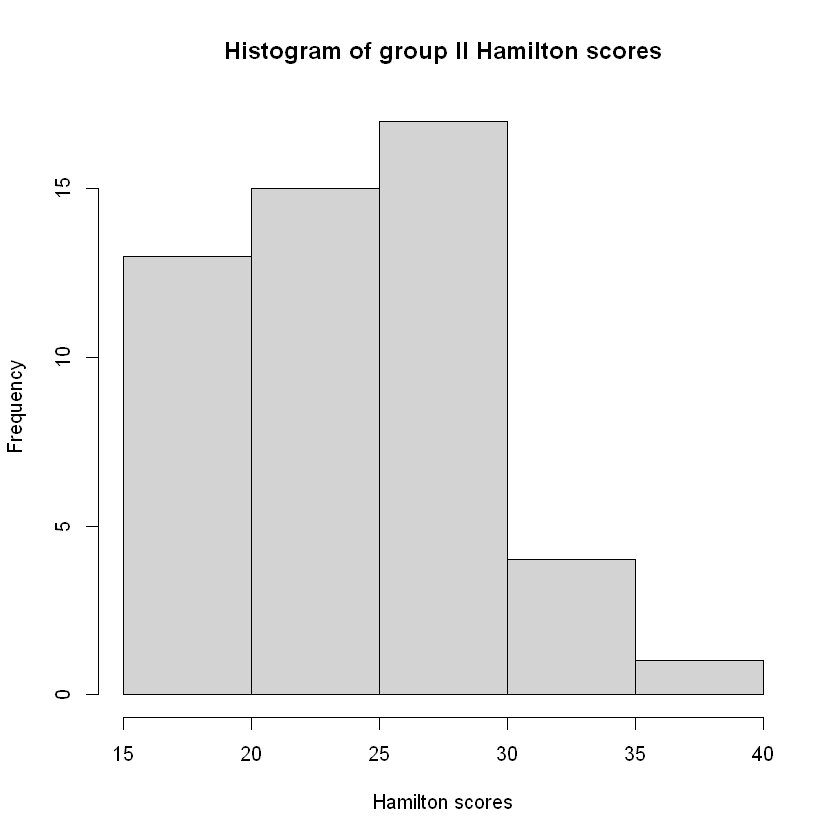

In [10]:
hist(hamilton_g2, main = "Histogram of group II Hamilton scores", xlab = "Hamilton scores")

**Comment:**

As observed previously we clearly observe that group II has a distribution with more frequent low Hamilton scores than grop II.

*Note: you can add a title to your plot by using the argument `main=` and putting a value in between quotes `"` like `hist(x, main = "Histogram of Hamilton score of patients in group I")`. You can do the same for x-axis and y-axis labels through the arguments `xlab` and `ylab`, respectively. These arguments will work the same for most graphical functions in R*. 

You can choose the number of classes in the histogram, which increases (or reduces) the precision of the graph.

Replot the histogram of `hamilton_g1` with 15 classes using the argument `n = 15` through the following syntax: `hist(..., n = X)`

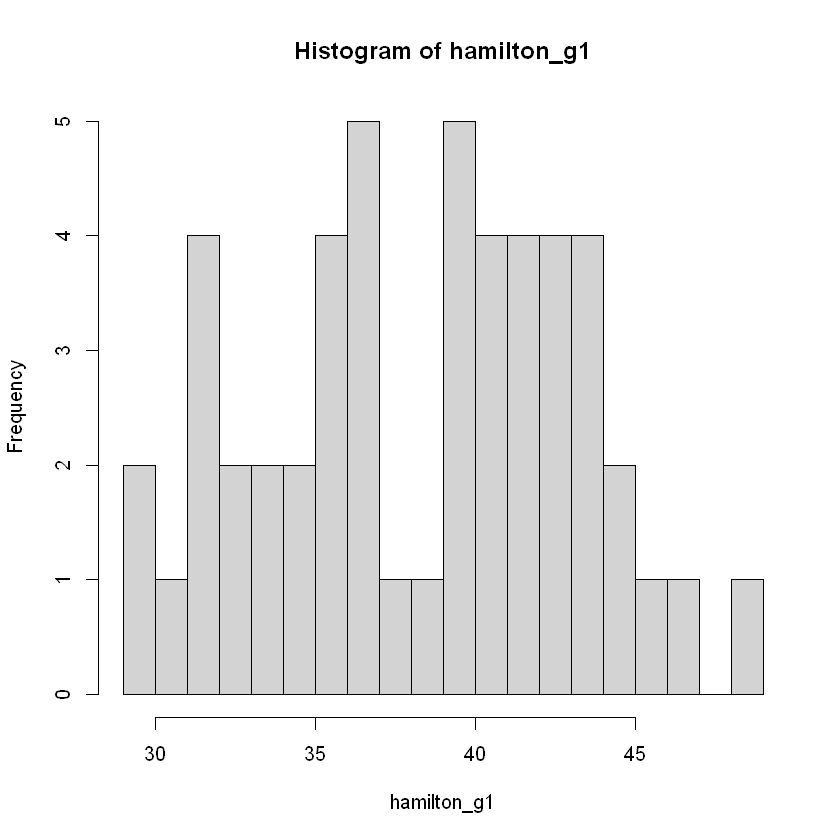

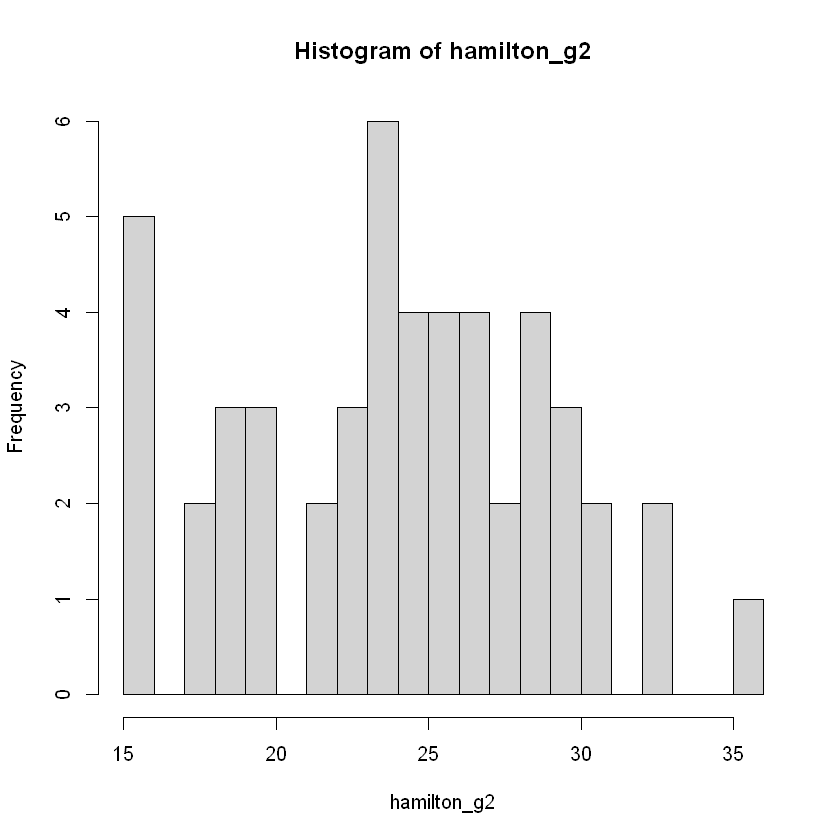

In [11]:
# Draw the histogram representing the hamilton_g1 variable, choosing 15 
# classes using argument n=15
hist(hamilton_g1, n = 15)

hist(hamilton_g2, n = 15)

**Comment:** When we split with many classes, the distribution can be more difficult to observe. But we confirm our previous observations.

#### The boxplot

This simple graph lets you quickly and visually summarize a variable, identify extreme values and understand the distribution of observations (dispersion, symmetry, etc.).
extreme values, understand the distribution of observations (dispersion, symmetry...) of a variable
of a variable, or to compare the distribution of data for the same variable between several
samples.

- The central value of the graph is the median (there are as many values above as below this value in the sample).
- The edges of the rectangle are the quartiles (for the lower edge, a quarter of observations have smaller values and three quarters have larger values; the upper edge follows the same reasoning).
- The ends of the whiskers are calculated using 1.5 times the interquartile range (the distance between the 1st and 3rd quartiles).
Note that 50% of observations are inside the box.

Values outside the box are represented by dots. These values can be
be described as extreme in relation to the other values in the sample. However
However, we mustn't make a quick shortcut and deduce that these are necessarily outliers. On the contrary, it indicates that these observations need to be studied in greater detail.

You can plot a boxplot in R with the function `boxplot()`.

*Application to the Hamilton score dataset:*

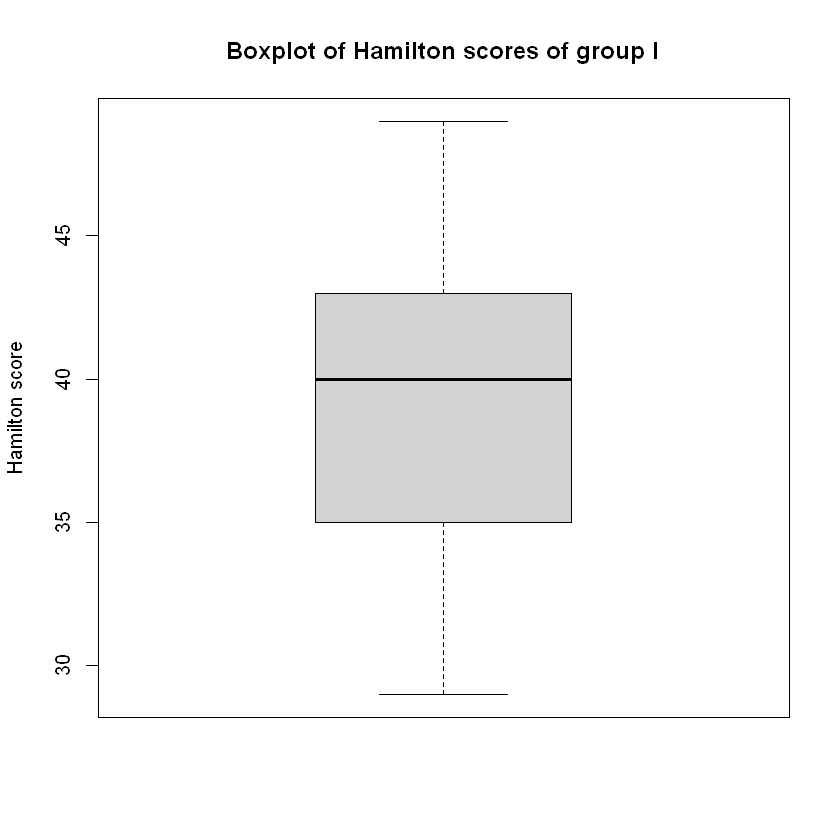

In [12]:
# Plot the boxplot of the Hamilton score of group G1
boxplot(hamilton_g1, main = "Boxplot of Hamilton scores of group I", ylab = "Hamilton score")

Plot the boxplot of the variable `hamilton_g2`

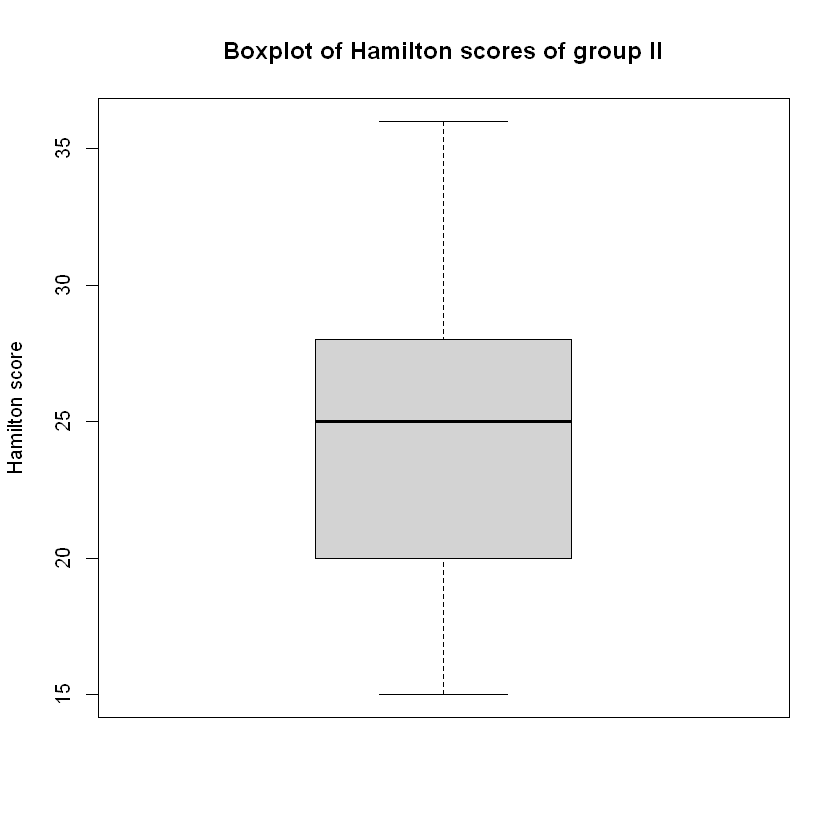

In [13]:
boxplot(hamilton_g2, main = "Boxplot of Hamilton scores of group II", ylab = "Hamilton score")

**Comment**

It's possible to plot both boxplots on the same figure through a few manipulations

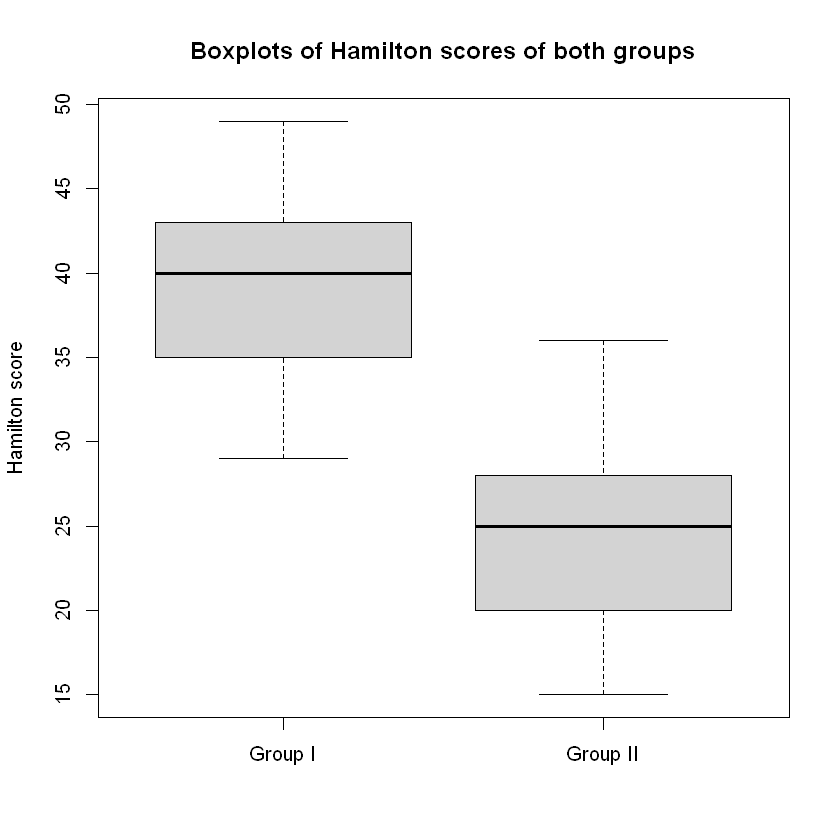

In [14]:
# Plot the boxplots
boxplot(hamilton_g1, hamilton_g2, main = "Boxplots of Hamilton scores of both groups", ylab = "Hamilton score", names = c("Group I", "Group II"))

### 3.4 Representation of qualitative variables

The description of a qualitative variable involves the presentation of its numbers by class.
This step is very important, as it enables us to check the distribution of numbers between classes. Thus, if a variable has a very unbalanced number of members in each class, this must be taken into account in future tests.
be taken into account in future tests, and in some cases it will be necessary to group the data
to avoid statistical bias.

*Application to the Urbanization variable*:

We want to compare the urbanization levels between groups 1 and 2. To do this, we'll create 2 variables:

- `urbanization_g1`, which will contain the urbanization level of group 1
- `urbanization_g2`, which will contain the urbanization level of group 2.

In [15]:
# urbanization_g1 which will contain the values of the group 1 urbanization variable
urbanization_g1 = depression$urbanization_g1
urbanization_g1

# urbanization_g2 which will contain the values of the group 2 urbanization variable
urbanization_g2 = depression$urbanization_g2
urbanization_g2

[1] "B" "A" "A" "A" "B" "B" "A" "A" "A" "A" "B" "A" "B" "A" "A" "B" "A" "B" "A"
[20] "A" "B" "B" "A" "A" "B" "B" "A" "A" "C" "B" "C" "B" "C" "A" "C" "A" "A" "B"
[39] "B" "B" "B" "B" "A" "A" "B" "B" "A" "A" "B" "C"

[1] "B" "B" "A" "A" "A" "B" "B" "A" "B" "A" "A" "A" "B" "A" "A" "B" "A" "B" "A"
[20] "B" "A" "A" "A" "B" "A" "B" "B" "B" "B" "B" "B" "A" "B" "A" "B" "B" "B" "A"
[39] "A" "B" "A" "B" "A" "A" "A" "B" "B" "B" "B" "A"

You can compute the number of observations in each level through the function `table()` for a qualitative variable.

In [16]:
# Show table of urbanization_g1
table(urbanization_g1)

urbanization_g1
 A  B  C 
24 21  5 

*Do the same for `urbanization_g2` and comment*

In [17]:
table(urbanization_g2)

urbanization_g2
 A  B 
24 26 

**Comment:**

Both groups show quite similar urbanization levels but group I has 5 persons coming from highly urbanized areas while group II has none.

#### Barplots

The height of the bars corresponds either to the frequency of observation of each of the modalities
or the size of the variable under consideration. Unlike histograms, the bars of bar charts are well separated
to emphasize the discrete nature of observations (as opposed to contiguity).
(as opposed to the contiguity of the bars in a histogram, which echoes the continuous nature of the variable).
of the variable).

You can plot them through the function `barplot()` in R. **It only works if you give it a vector of counts as input**.

*Application to the `urbanization_g1` variable:*

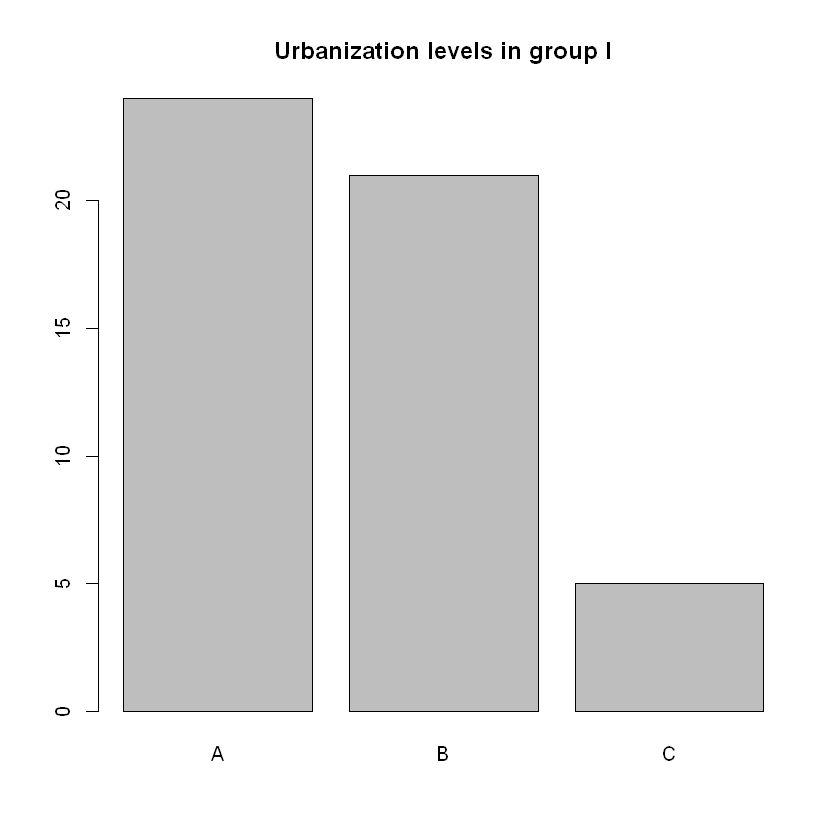

In [18]:
# Plot the barplot of urbanization_g1
barplot(table(urbanization_g1), main = "Urbanization levels in group I")

# This command doesn't work
# barplot(urbanization_g1)

Do the same for `urbanization_g2`

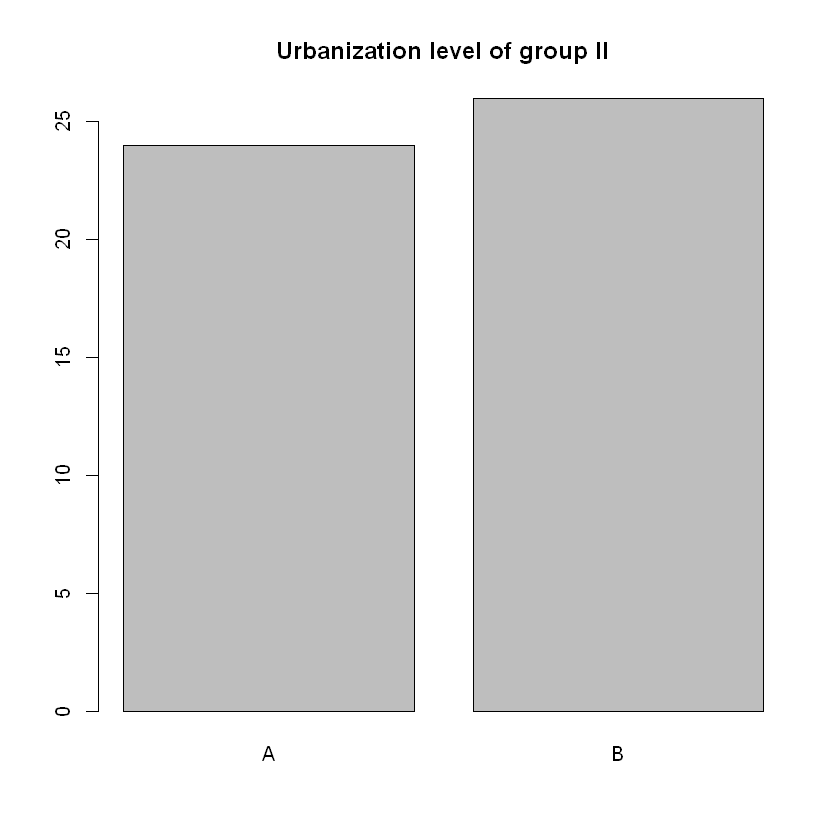

In [19]:
# Plot the barplot of urbanization_g2
barplot(table(urbanization_g2), main = "Urbanization level of group II")

**Comment:**

#### Pie charts

The pie chart represents the different modalities by angular sectors proportional to the observed frequencies.
to the observed frequencies.
Pie charts should be used sparingly, i.e. only when there are few modalities to represent.
there are few modalities to represent. The problem is that proportions are not very visible
with pie charts.

You can plot them through the function `pie()`. **It only works if you give it a vector of counts as input**.

*Application to the `urbanization_g1` variable:*

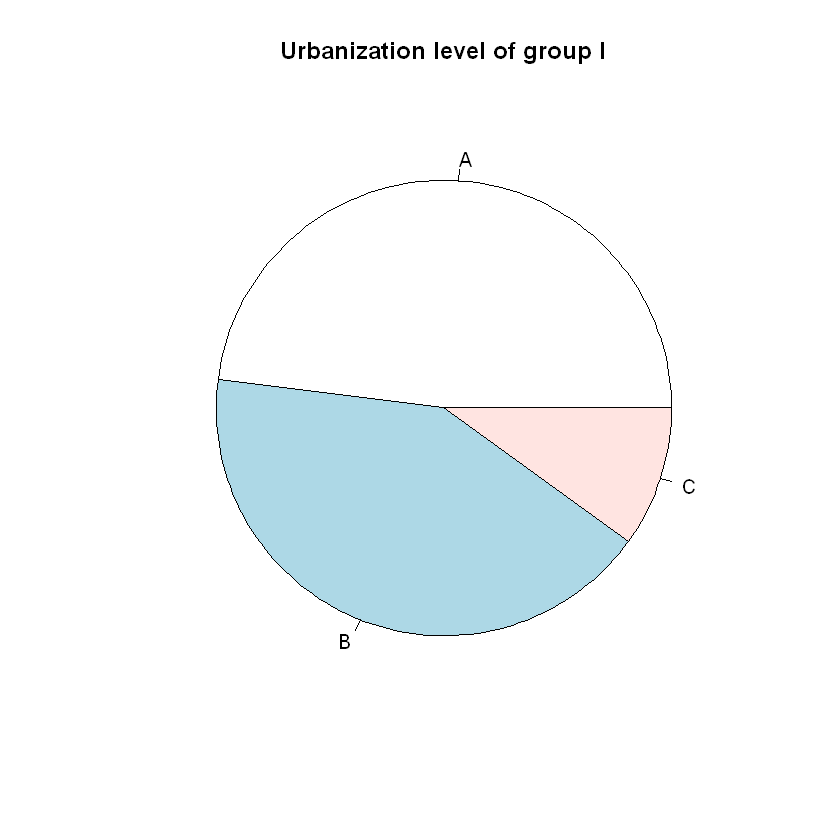

In [20]:
# Show urbanization_g1 pie chart
pie(table(urbanization_g1), main = "Urbanization level of group I")

Do thesame for `urbanization_g2`

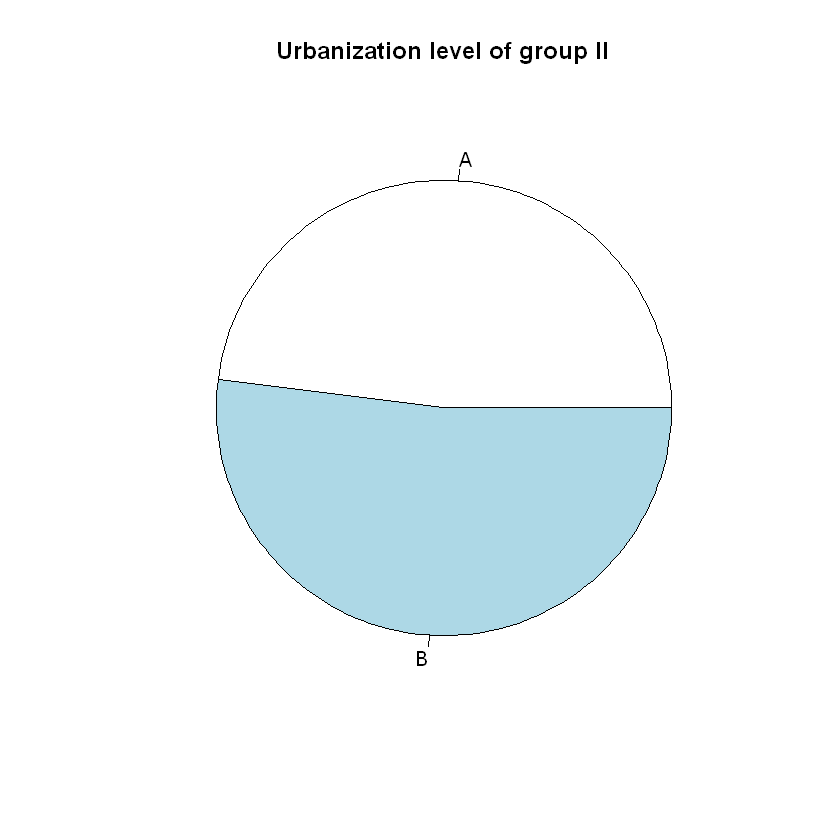

In [21]:
# Show urbanization_g2 pie chart
pie(table(urbanization_g2), main = "Urbanization level of group II")

**Comment:**

We confirm our previous observations with the proportions.

## 4. Data manipulation


### 4.1 Extracting a value from an array

With **R**, you can extract specific values from an array (`data.frame`). To do this, you need to be aware that an array is made up of rows and columns.
value has a row number *i* and a column number *j*. 

To extract a particular value from the array, simply specify its row and column number to **R**. For
example, we're going to extract the value of row 2 in column 3:

In [22]:
depression[2, 3]

[1] "A"

*Training: Extract the value from the table in row 15 and column 4:*.

In [23]:
depression[15, 4]

[1] "A"

Before going any further with sub-table extractions, it's important to understand the difference between `=` and `==`.

When we put a `=`, we're assigning a value. For example, here we're going to assign the value
value `4` to `toto` :

In [24]:
toto = 4
toto

[1] 4

When we put a **`==`**, we perform a test.

For example, we can test whether `toto` is equal to `9`.

In [25]:
toto == 9

# But
toto == 4

[1] FALSE

[1] TRUE

**R** answers that it's false.

**Note**: To test whether a value is different, use **`!=`**.

For example, you can test whether `toto` is $\neq$ 9 

In [26]:
toto != 9

toto != 4

[1] TRUE

[1] FALSE

**R** answers that it's true.

### 4.2 Condition-based sub-table extraction

#### Selecting data within a column

It is also possible to extract sub-groups of data within a column. For example, from our
our data table, we can extract from the Hamilton score column only the score for men.
the men's score. 

We'll call this new group `hamilton_men`.

The principle is as follows:
- We select the column we're interested in, in this case Hamilton.
- We are only interested in the men's score, so we need to specify to **R** that within this column, we will keep only the rows corresponding to men (using the `==` syntax ;))

In [27]:
# Create variable hamilton_men
hamilton_men = hamilton_g1[depression$sex_g1 == "H"]
hamilton_men

[1] 29 34 39 40 41 32 36 35 37 43 36 41 33 40 43 32 32 44 36 37 31 41 45 42 35
[26] 49 33 34 44 40 44 40 29 36 42 32 37 42 45

*Training: Extract Hamilton's score which is located in an
urbanized area A*.

In [28]:
# Create variable hamilton_urbanization_a
hamilton_urbanization_a = hamilton_g1[depression$urbanization_g1 == "A"]
hamilton_urbanization_a

[1] 29 34 39 32 36 35 37 36 37 33 38 32 32 36 37 37 31 35 33 34 29 36 32 37

#### Selecting a sub-table

It is also possible to extract a sub-table of data. For example, we'll
extract the array of data associated with group G1, which we'll call
`data_g1`. 

The principle is as follows:
- Locate the columns associated with groups G1: 1, 3, 5, 7 and 9.
- Next, we want to retrieve all rows

To do so we'll use the square brackets `[` and `]`, what's before the comma corresponds to the rows and what's after the comma corresponds to the columns. 
we don't specify anything for the rows because we want all the individuals, we specify that we want to keep only the columns containing `g1` in their names.

In [29]:
# Perform the extraction with the square brackets [] directly following the name of the dataset
data_g1 = depression[, c(1, 3, 5, 7, 9)]

# Display the first line of the new table
data_g1[1,]

# An alternative syntax is writing the column names directly
data_g1_bis = depression[, c("hamilton_g1", "urbanization_g1", "age_g1", "weight_g1", "sex_g1")]
data_g1_bis[1,]

,hamilton_g1,urbanization_g1,age_g1,weight_g1,sex_g1
,<int>,<chr>,<int>,<int>,<chr>
1,43,B,57,74,F


,hamilton_g1,urbanization_g1,age_g1,weight_g1,sex_g1
,<int>,<chr>,<int>,<int>,<chr>
1,43,B,57,74,F


*Application*: Create a new table `data_g2` containing only columns relevant for group II

In [30]:
data_g2 = depression[, c(2, 4, 6, 8, 10)]
head(data_g2)

,hamilton_g2,urbanization_g2,age_g2,weight_g2,sex_g2
,<int>,<chr>,<int>,<int>,<chr>
1,25,B,48,93,H
2,29,B,41,92,H
3,18,A,30,86,H
4,23,A,41,81,H
5,24,A,30,74,F
6,25,B,45,98,H


Application example: From the `data_g1` table, we'll select a new table containing only
array containing only the results for women. The principle is as follows:
- We keep only the rows where the value "F" appears in the sex column.
- Then we keep all the columns

In [31]:
# Create a sub-array called data_g1_women
data_g1_women = data_g1[data_g1$sex_g1 == "F",]

# display the first lines of the data.frame
head(data_g1_women)

,hamilton_g1,urbanization_g1,age_g1,weight_g1,sex_g1
,<int>,<chr>,<int>,<int>,<chr>
1,43,B,57,74,F
14,37,A,39,72,F
17,38,A,44,71,F
22,40,B,62,72,F
24,37,A,45,73,F
25,41,B,56,67,F


Extract a table `data_g2_women` containing only information about women in group II

In [32]:
data_g2_women = data_g2[data_g2$sex_g2 == "F",]
data_g2_women

,hamilton_g2,urbanization_g2,age_g2,weight_g2,sex_g2
,<int>,<chr>,<int>,<int>,<chr>
5,24,A,30,74,F
11,18,A,29,66,F
33,33,B,38,74,F
42,26,B,38,74,F
45,23,A,37,73,F


**Note**: It is possible to combine several conditions when extracting data from a table using the intructions :
- **`&`** meaning “and”: for example, we want to extract from the table data concerning women over 40 (which translates as “being a woman and over 40”).
- **`|`** which means “or”: for example, we want to extract from the table the data concerning either women or people over 40. The difference with the previous table is that in this table it will also be possible to have men over 40.

*Apply these two conditions to the table `data_g1`*.

In [33]:
# Create table tab1 containing only women over 40 from table data_g1 
tab1 = data_g1[data_g1$sex_g1 == "F" & data_g1$age_g1 >= 40,]
head(tab1)

# Create table tab2 containing women or people over 40 from table data_g1 
tab2 = data_g1[data_g1$sex_g1 == "F" | data_g1$age_g1 >= 40,]
head(tab2)

,hamilton_g1,urbanization_g1,age_g1,weight_g1,sex_g1
,<int>,<chr>,<int>,<int>,<chr>
1,43,B,57,74,F
17,38,A,44,71,F
22,40,B,62,72,F
24,37,A,45,73,F
25,41,B,56,67,F
26,43,B,40,65,F


,hamilton_g1,urbanization_g1,age_g1,weight_g1,sex_g1
,<int>,<chr>,<int>,<int>,<chr>
1,43,B,57,74,F
6,41,B,45,85,H
7,32,A,41,79,H
9,35,A,55,76,H
10,37,A,46,78,H
14,37,A,39,72,F


*Same for `data_g2`*

In [34]:
# Create table tab1_bis containing only women over 40 from table data_g2 
tab1_bis = data_g2[data_g2$sex_g2 == "F" & data_g2$age_g2 >= 40,]
head(tab1_bis)

# Create table tab2_bis containing women or people over 40 from table data_g2 
tab2_bis = data_g2[data_g2$sex_g2 == "F" | data_g2$age_g2 >= 40,]
head(tab2_bis)

hamilton_g2,urbanization_g2,age_g2,weight_g2,sex_g2
<int>,<chr>,<int>,<int>,<chr>


,hamilton_g2,urbanization_g2,age_g2,weight_g2,sex_g2
,<int>,<chr>,<int>,<int>,<chr>
1,25,B,48,93,H
2,29,B,41,92,H
4,23,A,41,81,H
5,24,A,30,74,F
6,25,B,45,98,H
7,27,B,41,75,H


*Application:*
- Build a table named `tabA_and` that selects women and the class Urbanization “A”. 
- Construct a table named `tabA_or` that selects women or the class Urbanization “A”. 

In [35]:
# Build an array named tabA_and that selects women and the class Urbanization “A”. 
tabA_and = data_g1[data_g1$sex_g1 == "F" & data_g1$urbanization_g1 == "A",]
head(tabA_and)

# Build an array named tabA_or that selects women or the class Urbanization “A”.
tabA_or = data_g1[data_g1$sex_g1 == "F" | data_g1$urbanization_g1 == "A",]
head(tabA_or)

,hamilton_g1,urbanization_g1,age_g1,weight_g1,sex_g1
,<int>,<chr>,<int>,<int>,<chr>
14,37,A,39,72,F
17,38,A,44,71,F
24,37,A,45,73,F


,hamilton_g1,urbanization_g1,age_g1,weight_g1,sex_g1
,<int>,<chr>,<int>,<int>,<chr>
1,43,B,57,74,F
2,29,A,37,95,H
3,34,A,7,84,H
4,39,A,37,104,H
7,32,A,41,79,H
8,36,A,33,92,H


## 5. Application exercises

### 5.1 Data extraction

From data_Depression :
1. Extract the table of data for men in group G1, which we'll call `data_g1_men`. 
2. Extract the data table for men in group G2, which we'll call `data_g2_men`.




### 5.2 Comparative study of Hamilton scores for men of both groups

From these two data tables, carry out a comparative descriptive study by answering the following questions:

1. Compare the empirical means and variances of the men's Hamilton scores in the two tables.
2. Compare the empirical medians and quartiles of the men's ages in the two tables.




In [36]:
mean(data_g1[data_g1$sex_g1 == "H", "hamilton_g1"])
mean(data_g2[data_g2$sex_g2 == "H", "hamilton_g2"])

sd(data_g1[data_g1$sex_g1 == "H", "hamilton_g1"])
sd(data_g2[data_g2$sex_g2 == "H", "hamilton_g2"])

summary(data_g1[data_g1$sex_g1 == "H", "hamilton_g1"])
summary(data_g2[data_g2$sex_g2 == "H", "hamilton_g2"])

[1] 37.97436

[1] 24.51111

[1] 4.981477

[1] 5.020966

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  29.00   34.00   37.00   37.97   42.00   49.00 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  15.00   20.00   25.00   24.51   28.00   36.00 

What hypotheses can you make?

We made the hypotheses above in the document (acupuncture treatment seems to reduce depression score as group II has overall lower Hamilton scores than group I).

### 5.3 Comparison of men's Hamilton score according to urbanization of their place of residence


1. Plot the Hamilton score of men in group I who live in type A urbanized areas.
2. Plot the Hamilton score of men in group I who live in type B urbanized areas.
3. Plot the Hamilton score of men in group II who live in type A urbanized areas.
4. Plot the Hamilton score of men in group II who live in type B urbanized areas.

What hypotheses can you form from these descriptions? 

[1] 29 34 39 32 36 35 37 36 33 32 32 36 37 31 35 33 34 29 36 32 37

[1] 40 41 43 41 40 43 44 41 42 44 40 44 40 42 42

[1] 18 23 16 16 19 20 16 23 24 24 16 24 15 22 22 20 20 19 19 24 24

[1] 25 29 25 27 27 26 28 29 27 28 30 31 29 26 27 36 33 31 30 29 26 25 25 30

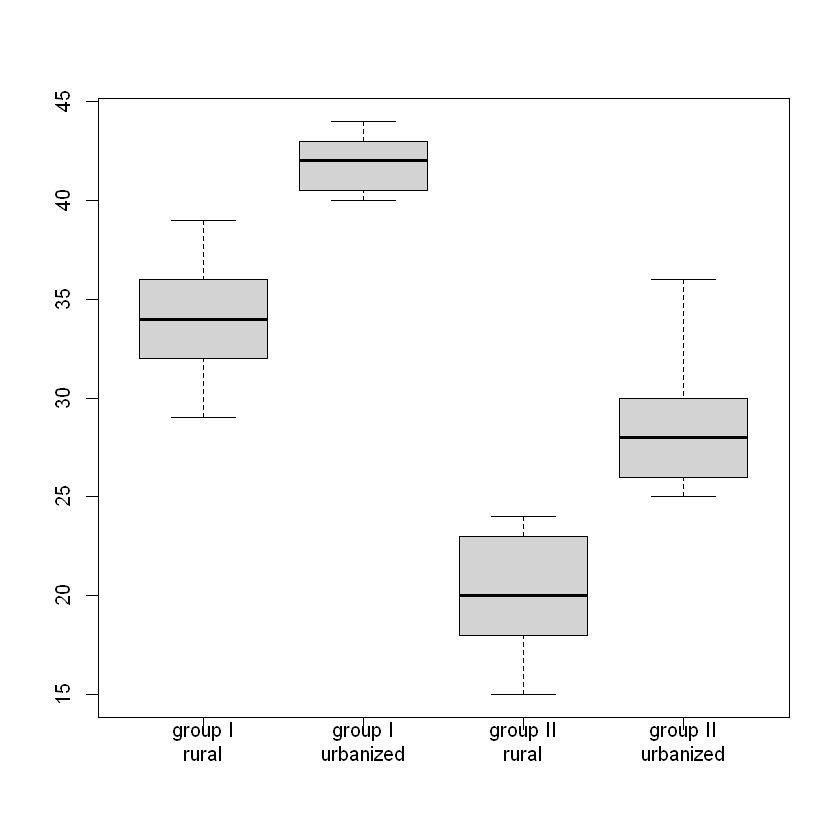

In [37]:
g1_a = data_g1[data_g1$sex_g1 == "H" & data_g1$urbanization_g1 == "A", "hamilton_g1"]
g1_b = data_g1[data_g1$sex_g1 == "H" & data_g1$urbanization_g1 == "B", "hamilton_g1"]
g2_a = data_g2[data_g2$sex_g2 == "H" & data_g2$urbanization_g2 == "A", "hamilton_g2"]
g2_b = data_g2[data_g2$sex_g2 == "H" & data_g2$urbanization_g2 == "B", "hamilton_g2"]

g1_a
g1_b
g2_a
g2_b

boxplot(g1_a, g1_b, g2_a, g2_b, names = c("group I\nrural", "group I\nurbanized", "group II\nrural", "group II\nurbanized"))

It seems that acupuncture has an effect but joint with urbanization. People living in rural places show overall lower average Hamilton scores than ones living in urbanized environments.